# Del costo programado al ejecutado: análisis de desviaciones de un pozo exploratorio

Proyecto final de Ciencia de Datos · Universidad Anáhuac Puebla

Este notebook recorre las seis fases del análisis de datos (Ask, Prepare, Process, Analyze, Share y Act) con el paquete `costos`.

**Confidencialidad.** Los datos reales son confidenciales. Aquí se usa un **pozo sintético** que imita la estructura del caso y reproduce los mismos tipos de problemas. Al final se reproducen las figuras del documento con los **índices anonimizados** publicados en él.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/toledotoop90-coder/control-desviaciones-pozo/blob/main/notebooks/analisis_seis_fases.ipynb)

**Para correrlo sin instalar nada:** abra el botón *Abrir en Colab* y use *Entorno de ejecución → Ejecutar todas*. La primera celda descarga e instala el paquete; tarda menos de un minuto.

In [1]:
# Preparación: en Google Colab (o en cualquier entorno sin el paquete) descarga el repositorio y lo instala.
# En una instalación local con `pip install -e .` esta celda no hace nada.
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/toledotoop90-coder/control-desviaciones-pozo"
if importlib.util.find_spec("costos") is None:
    destino = Path("control-desviaciones-pozo")
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(destino)], check=True)
    os.chdir(destino)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(Path("src").resolve()))
print("Paquete listo en", Path.cwd())

Paquete listo en /home/claude/control-desviaciones-pozo/notebooks


In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from costos import calidad, indicadores, modelo, pipeline, sintetico, validacion
from costos.config import Config
from costos.io import cargar_pozo

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data" / "sintetico"
SALIDA = RAIZ / "reports" / "notebook"
cfg = Config()
cfg

Config(descuento=0.07, contratos_con_descuento=('A', 'B'), tolerancia_redondeo=0.005, tolerancia_cuadre=0.01, umbral_justificacion=0.0, unidades_por_metro=('METRO PERFORADO', 'METRO'))

## 1. Ask: el problema y las preguntas

**Problema.** La empresa no puede explicar a tiempo, y partida por partida, por qué el costo ejecutado de un pozo exploratorio se aparta de la cédula autorizada.

| # | ¿Por qué? | Respuesta |
| --- | --- | --- |
| 1 | ¿Por qué se cuestiona el costo? | Lo ejecutado difiere de la cédula y se explica al final, en totales |
| 2 | ¿Por qué al final y en totales? | Se comparan montos agregados, no partidas |
| 3 | ¿Por qué no partidas? | VO, SIS y campo viven en archivos distintos, sin clave común |
| 4 | ¿Por qué no hay clave común? | El proceso de diseño termina en la cédula y no define el seguimiento |
| 5 | ¿Por qué no se define? | Se mide el total contra la Clase 2, no la trazabilidad |

**Preguntas de investigación**

- **PI1.** ¿Cuánto se desvía lo ejecutado del VO y dónde se concentra?
- **PI2.** ¿Qué parte es operativa y qué parte viene del VO?
- **PI3.** ¿Qué relación hay entre la duración de la etapa y su costo?
- **PI4.** ¿Qué tan soportadas están las justificaciones?

## 2. Prepare: fuentes y calidad

Se generan las fuentes sintéticas y se evalúa su calidad con las categorías de Wang y Strong (1996).

In [3]:
sintetico.generar(DATOS)
fuentes = cargar_pozo(DATOS)
pozo = fuentes["cedula"]["pozo"]
print("Pozo:", pozo, "| renglones VO:", len(fuentes["vo"]), "| renglones ejecutado:", len(fuentes["ejecutado"]))
fuentes["vo"].head()

Pozo: POZO-DEMO | renglones VO: 26 | renglones ejecutado: 25


,pozo,etapa,partida,descripcion,unidad,contrato,subrubro,cantidad,pu
0,POZO-DEMO,1-30,3.05,"Servicio integrado de perforación, conductor 3...",METRO PERFORADO,A,1.2.03 Perforación por etapas,50,"1,800.55"
1,POZO-DEMO,1-30,2.72,Servicio integral de membrana,DIA,A,1.2.02 Equipo de perforación y terminación,6,595.45
2,POZO-DEMO,1-30,5.83,Tanque recirculador para preparar baches,OPERACION,A,1.2.05 Cementación,1,"1,550.47"
3,POZO-DEMO,1-30,6.78,Aplicación de viscosificante,KG,A,1.2.06 Fluidos de perforación,1000,19.54
4,POZO-DEMO,1-30,6.90.,Material sellante y obturante,KG,A,1.2.06 Fluidos de perforación,800,1.38


In [4]:
hallazgos = calidad.evaluar(fuentes["vo"], fuentes["ejecutado"], fuentes["etapas"], pozo, cfg)
hallazgos[["categoria", "regla", "fuente", "renglones", "detalle", "tratamiento"]]

,categoria,regla,fuente,renglones,detalle,tratamiento
0,Representación,Clave de partida con formato irregular,vo,1,Ejemplos: 6.90.,Se normaliza como texto sin punto final
1,Intrínseca,Renglón duplicado,ejecutado,1,Renglones idénticos en todas las columnas,Se conserva uno; no se suma dos veces
2,Intrínseca,Valor faltante,ejecutado,1,Columna 'unidad' vacía,Se reporta; no se imputa ningún valor
3,Contextual,Renglones de otro pozo,ejecutado,1,Pozos encontrados: POZO-OTRO,Se excluyen del análisis
4,Intrínseca,Precio del VO sin descuento contractual,vo,8,8 de 26 renglones (31%); VO sobreestimado 2.7%,Se separa como efecto descuento VO; no se cuen...
5,Intrínseca,Metros del VO distintos al programa,vo,1,"Etapa 2-20, partida 3.10: VO 1,150 m contra pr...",Se reporta como error de planeación del VO


Los dos hallazgos más graves son los precios del VO sin descuento y los metros del VO distintos al programa: sin separarlos, se contarían como ahorro.

## 3. Process: limpieza, transformación y validación

El análisis completo vive en `pipeline.analizar`: filtra el pozo, quita duplicados exactos, normaliza claves y precios, y valida.

In [5]:
res = pipeline.analizar(DATOS, cfg)
res.validacion

,prueba,que_verifica,esperado,obtenido,resultado
0,Cuadre VO contra cédula,La base de comparación es la oficial,"2,076,843.19","2,076,843.19",OK
1,Conservación del VO,Ningún renglón del VO se pierde al normalizar,"2,076,843.19","2,076,843.19",OK
2,Conservación del ejecutado,Ningún renglón del ejecutado se pierde al norm...,"1,778,779.61","1,778,779.61",OK
3,Aditividad de los efectos,Los cinco efectos suman la desviación de cada ...,0.00,0.00,OK
4,Desviación total,La suma de desviaciones es ejecutado menos VO ...,"-283,877.96","-283,877.96",OK


## 4. Analyze: modelo seleccionado y hallazgos

**Por qué este modelo.** La pregunta es diagnóstica (explicar lo que ya pasó), la fórmula del costo se conoce (monto = cantidad × precio) y el resultado debe cuadrar al peso. Por eso se usa un análisis de variaciones determinístico y no un modelo predictivo. MSE y R² no aplican: el modelo no estima, descompone.

Cada desviación se divide en cinco efectos que suman exacto:

`desviación = descuento VO + cantidad + precio + nuevas − no usadas`

In [6]:
cols = [
    "etapa",
    "partida",
    "efecto_descuento",
    "efecto_cantidad",
    "efecto_precio",
    "partida_nueva",
    "partida_no_usada",
    "desviacion",
    "requiere_justificacion",
    "motivo",
]
res.comparativa[cols]

,etapa,partida,efecto_descuento,efecto_cantidad,efecto_precio,partida_nueva,partida_no_usada,desviacion,requiere_justificacion,motivo
0,1-30,2.72,0.00,-416.82,0.00,0.00,0.00,-416.82,True,Efecto cantidad
1,1-30,3.05,"-6,301.93","-10,047.07",0.00,0.00,0.00,"-16,348.99",True,Efecto cantidad
2,1-30,5.83,-108.53,0.00,0.00,0.00,0.00,-108.53,False,Solo efecto descuento VO (no requiere justific...
3,1-30,6.114,0.00,0.00,0.00,"3,601.74",0.00,"3,601.74",True,Partida nueva
4,1-30,6.117,-109.38,-242.21,0.00,0.00,0.00,-351.59,True,Efecto cantidad
5,1-30,6.174,-0.00,"-3,477.14",0.00,0.00,0.00,"-3,477.14",True,Efecto cantidad
6,1-30,6.78,0.00,0.00,0.00,0.00,"-19,539.30","-19,539.30",True,Partida no usada
7,1-30,6.90,-0.00,-206.46,0.00,0.00,0.00,-206.46,True,Efecto cantidad
8,1-30,9.46,0.00,-321.88,0.00,0.00,0.00,-321.88,True,Efecto cantidad
9,2-20,2.72,0.00,"3,274.98",0.00,0.00,0.00,"3,274.98",True,Efecto cantidad


In [7]:
# Prueba de aditividad: debe estar vacía
validacion.aditividad(res.comparativa)

,etapa,partida,desviacion,suma_efectos


### PI1 y PI2: cuánto, dónde y qué parte viene del VO

In [8]:
r = res.resumen_etapa[
    [
        "etapa",
        "monto_vo_comparable",
        "importe_real",
        "efecto_descuento",
        "desviacion_operativa",
        "pct_desviacion",
        "pct_operativa",
        "partidas_a_justificar",
    ]
]
r

,etapa,monto_vo_comparable,importe_real,efecto_descuento,desviacion_operativa,pct_desviacion,pct_operativa,partidas_a_justificar
0,1-30,"127,335.43","90,166.45","-6,519.84","-30,649.14",-0.29,-0.24,8
1,2-20,"828,500.06","583,149.55","-49,857.04","-195,493.47",-0.30,-0.24,13
2,3-16,"1,106,822.09","1,105,463.61",-0.00,"-1,358.48",-0.00,-0.00,2


In [9]:
modelo.participacion_operativa(res.comparativa)

,subrubro,desviacion_operativa,participacion_pct
0,1.2.03 Perforación por etapas,"-148,255.02",65.17
1,1.2.06 Fluidos de perforación,"-43,583.98",19.16
2,1.2.04 Perforación direccional,"-38,691.72",17.01
3,1.2.09 Recuperación de fluidos,"-1,931.29",0.85
4,1.2.05 Cementación,-631.86,0.28
5,1.2.07 Registros geofísicos,"2,139.18",-0.94
6,1.2.02 Equipo de perforación y terminación,"3,453.62",-1.52


### PI3: tiempo contra costo

In [10]:
t = fuentes["etapas"].merge(res.resumen_etapa[["etapa", "pct_desviacion"]], on="etapa")
t["dias_vs_programa"] = t["dias_real"] / t["dias_programa"] - 1
t[["etapa", "estado", "dias_vs_programa", "pct_desviacion"]]

,etapa,estado,dias_vs_programa,pct_desviacion
0,1-30,cerrada,-0.20,-0.29
1,2-20,cerrada,0.50,-0.30
2,3-16,abierta,NaN,-0.00


Con dos etapas cerradas no hay base para una relación estadística: una asociación no prueba causalidad.

### PI4: soporte de las justificaciones

In [11]:
j = fuentes["justificaciones"].copy()
j["soporte_valido"] = [indicadores.soporte_valido(t, f) for t, f in zip(j["tipo_soporte"], j["folio_soporte"], strict=True)]
j[["etapa", "partida", "causa", "tipo_soporte", "folio_soporte", "soporte_valido"]]

,etapa,partida,causa,tipo_soporte,folio_soporte,soporte_valido
0,1-30,3.05,Desempeño real de la etapa,ESTADO MECANICO,EM-DEMO-014,True
1,1-30,6.78,Condición prevista que no se presentó,,,False
2,1-30,6.114,Planeación del VO,SIS COMPLEMENTARIA,,False
3,1-30,6.174,Optimización,MINUTA,MIN-DEMO-033,True
4,2-20,3.10,Desempeño real de la etapa,REPORTE DIARIO,RD-DEMO-118,True
5,2-20,4.186,Condición prevista que no se presentó,,,False


## 5. Share: visualizaciones

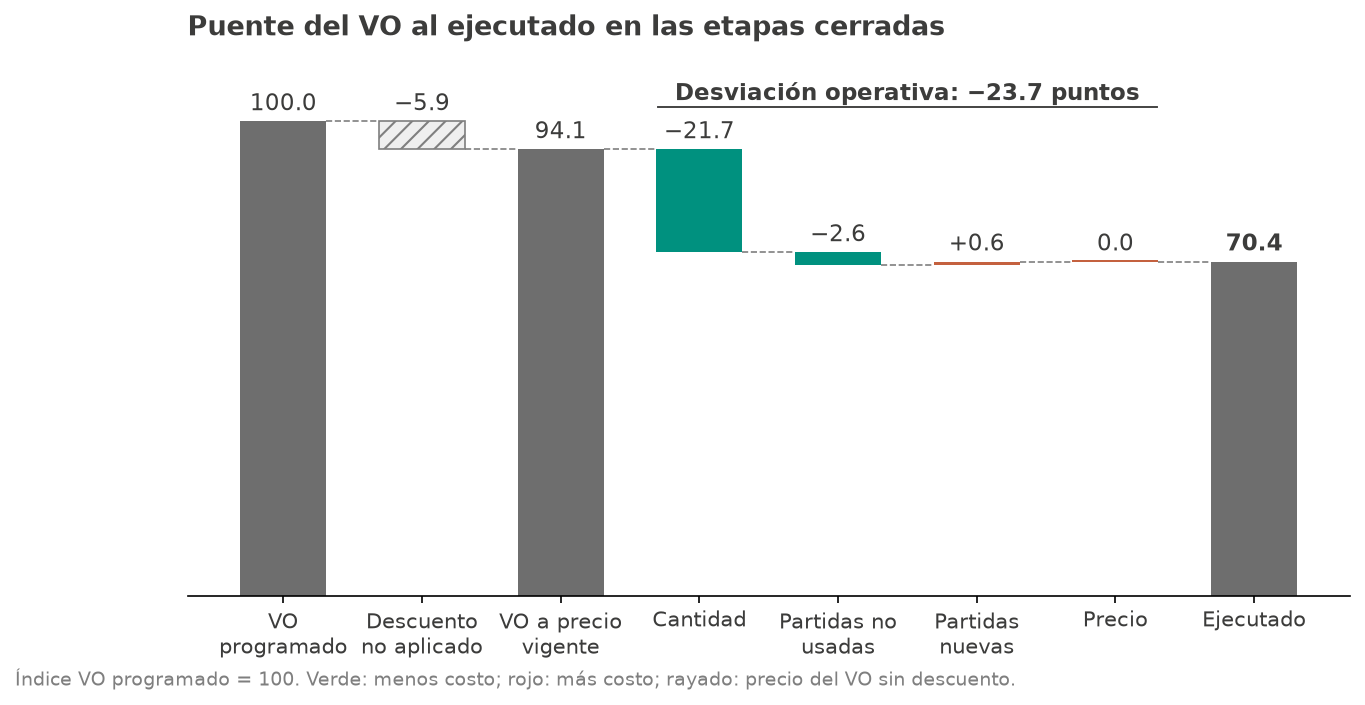

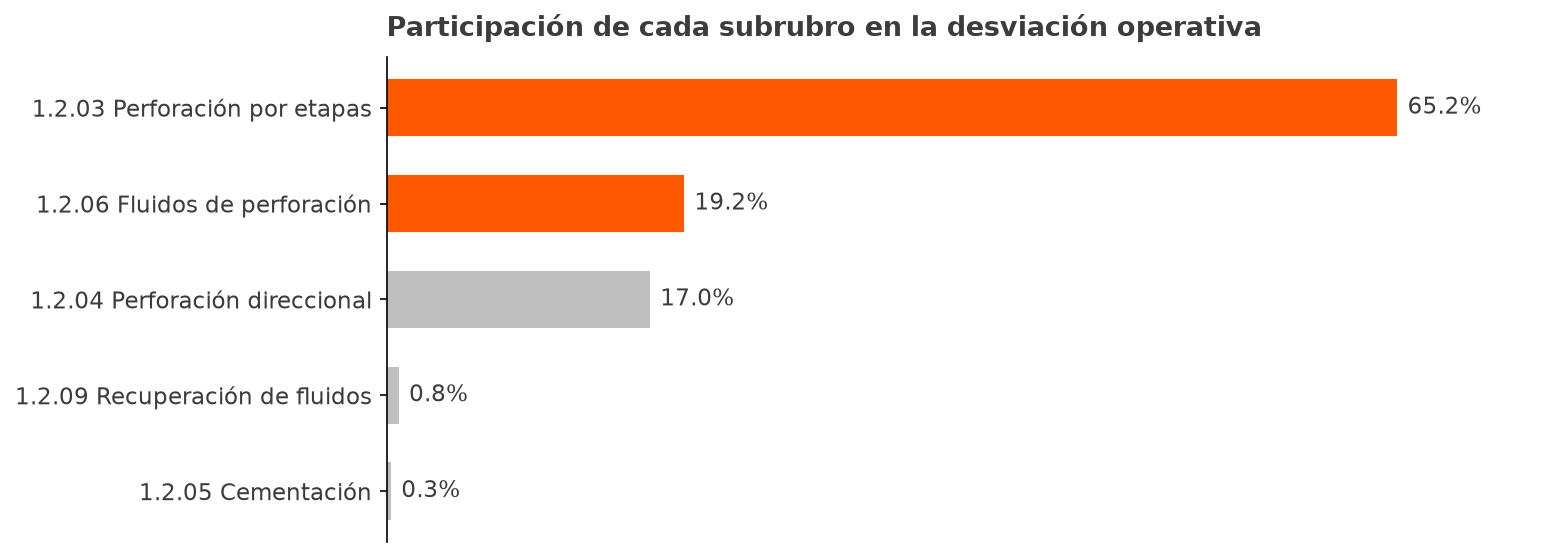

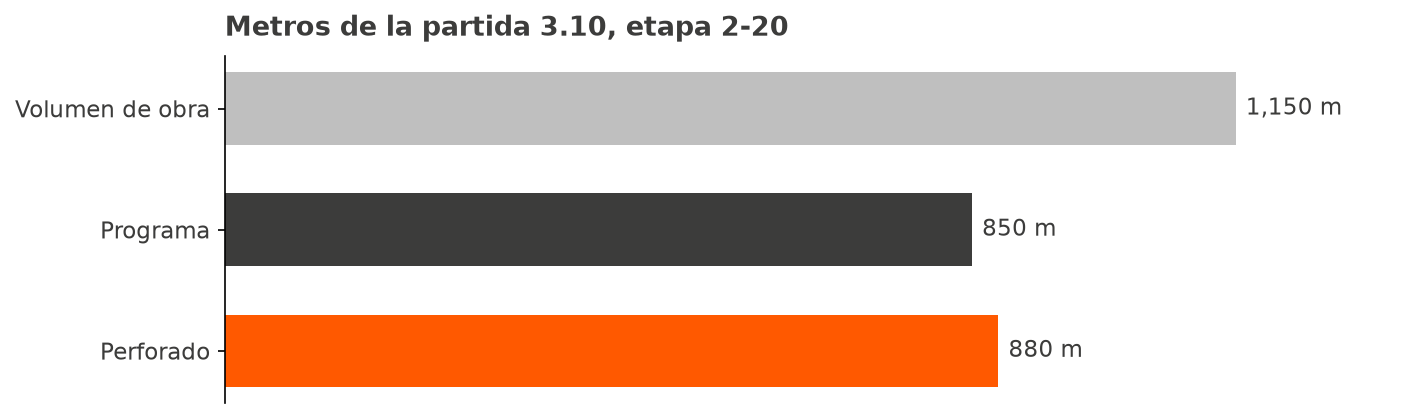

In [12]:
rutas = pipeline.figuras(res, fuentes["etapas"], SALIDA)
for r in rutas:
    display(Image(filename=str(r), width=760))

## 6. Act: indicadores (línea base)

Las metas son propuestas del equipo para validar con el área; el impacto es esperado, no comprobado.

In [13]:
res.indicadores

,indicador,formula,linea_base,meta,frecuencia
0,Justificaciones con soporte válido,Con soporte válido ÷ revisadas,0.50,0.90,Por etapa
1,Partidas a justificar,Partidas con desviación operativa,23.00,NaN,Por etapa
2,Descuento aplicado en el VO,Renglones con descuento ÷ renglones del contrato,0.69,1.00,Por VO
3,Metros del VO contra programa,Máxima |VO − programa| ÷ programa,0.35,0.00,Por VO


## Figuras del documento con los índices anonimizados del Pozo A

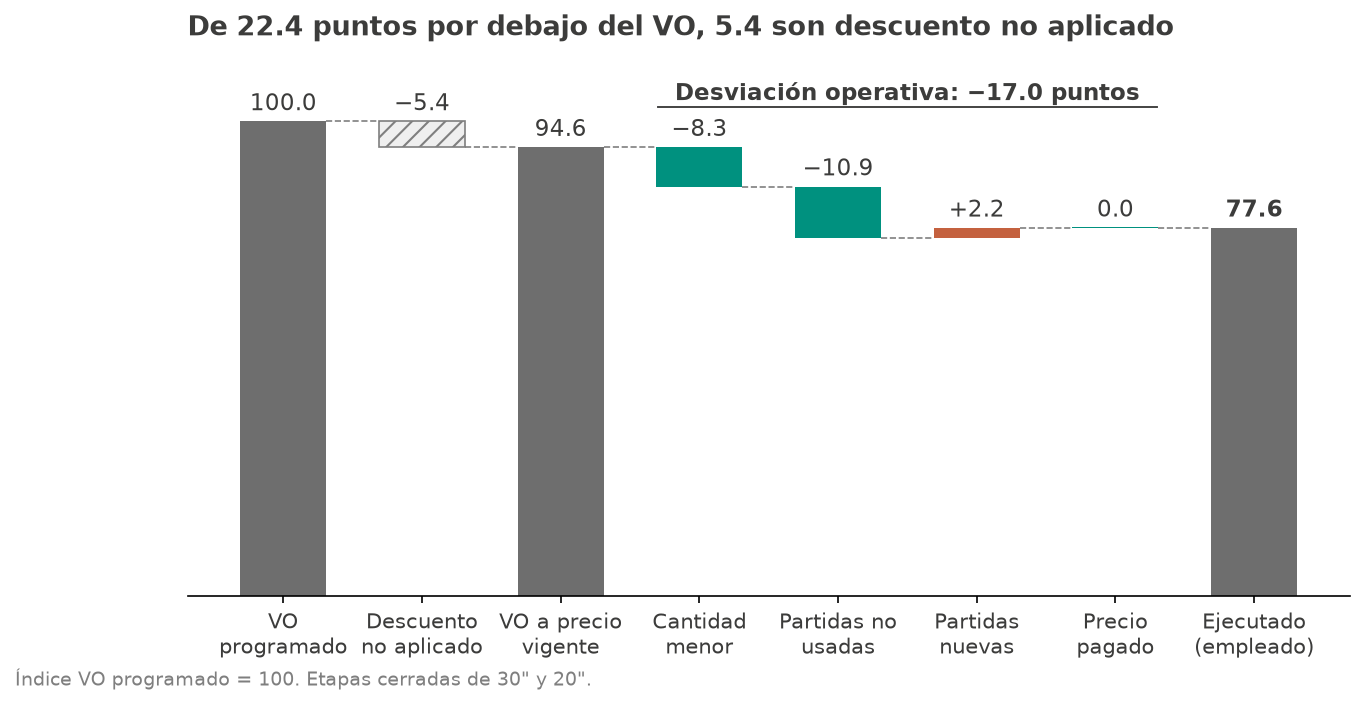

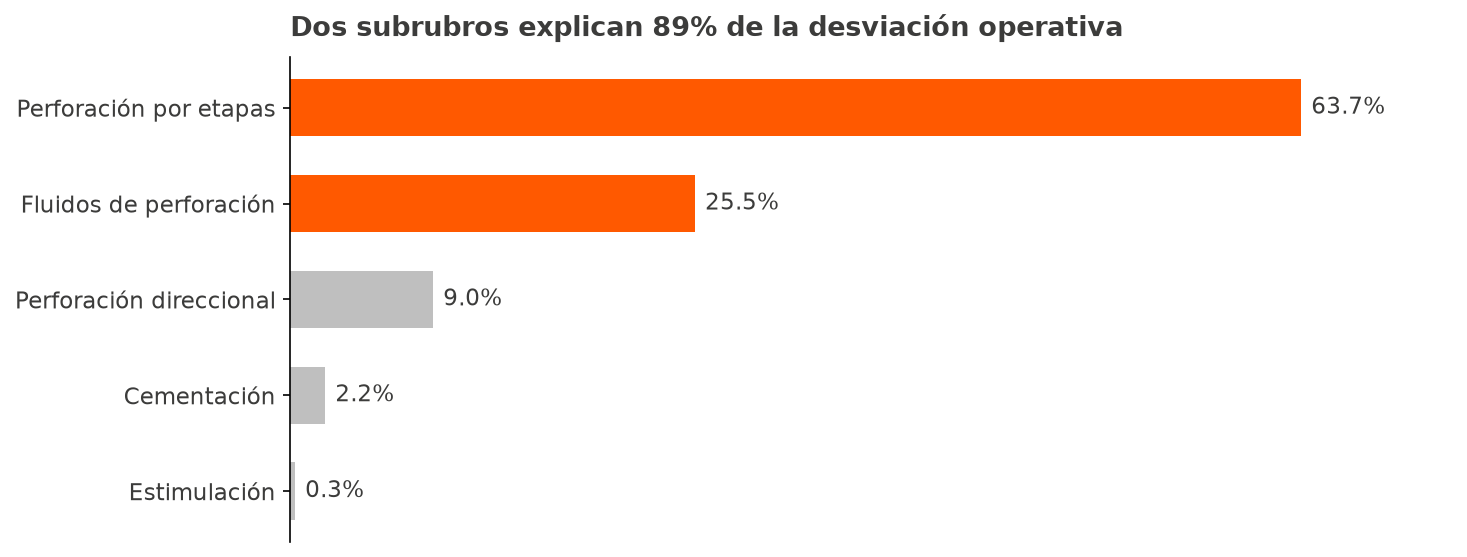

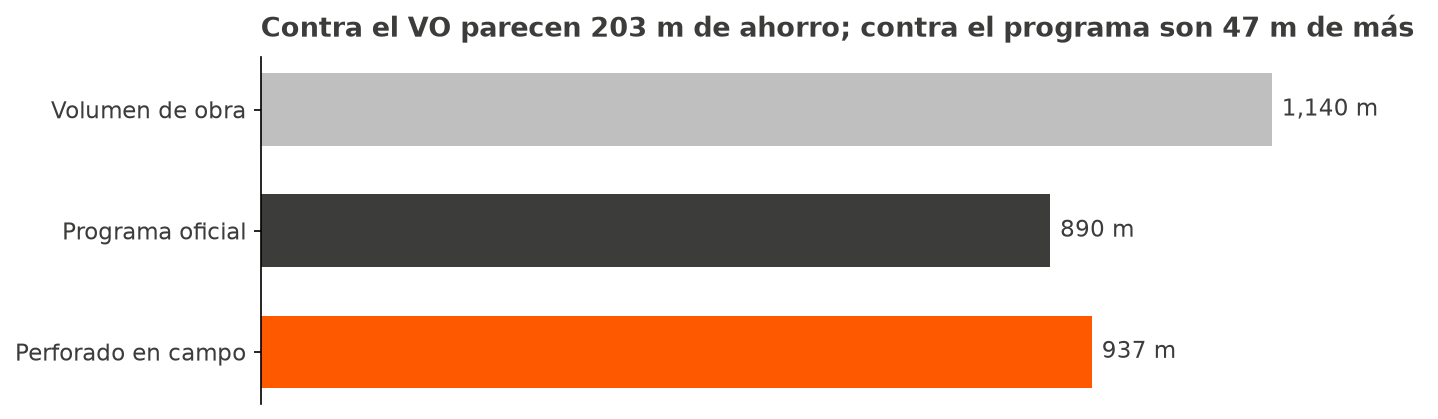

In [14]:
for r in pipeline.figuras_documento(RAIZ / "data" / "anonimizado", RAIZ / "reports" / "figuras_documento"):
    display(Image(filename=str(r), width=760))

## Conclusiones y limitaciones

- La desviación se explica partida por partida cuando las fuentes comparten clave y reglas.
- Parte del aparente ahorro es un error del VO (descuento y metros), no de la operación.
- El modelo atribuye montos; la causa la prueba la evidencia del ingeniero.
- Limitaciones: un pozo, datos sintéticos en este notebook, precio base deducido del VO, sin rubro Equipo.